In [40]:
import networkx as nx
import rustworkx as rx
import re

import osmnx as ox
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import itertools as it
from tqdm import tqdm
import logging
import operator
from shapely.geometry import LineString, Point
import pandas as pd
import datetime
import geopandas as gpd
import movingpandas as mpd

import sys
from pathlib import Path

#Truc moche pour que les imports de src marchent
current_file = Path.cwd()
project_root = current_file.parents[0]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.sim import Sim, Car, Display, select_min_weight_lane
from src.demand import trajs_rdm, trajs_bc_test
from src.unit_tests import UnitTest
from src.rustworkx_helper import rx_helper
from src.routingkit_helper import rk_helper
from src.preprocessing import preprocessing

np.random.seed(1)

ox.__version__

'2.1.1'

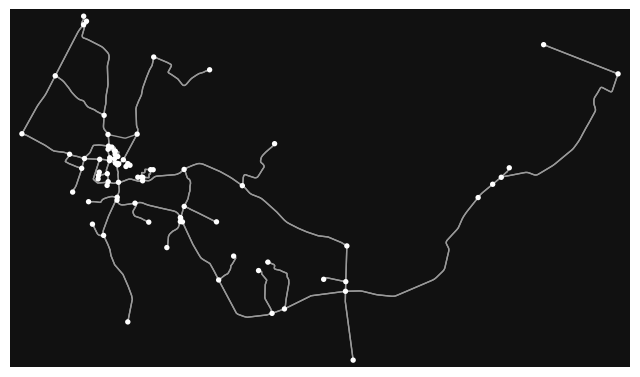

In [41]:
data_dir=Path('/home/lucas/Documents/test/sim/data')
# download/model a street network for some city then visualize it
prep=preprocessing()
city=f"Cudos, France"
# city=f"Piedmont, California, USA"
city_name=city[:re.search(', ', city).span(0)[0]].lower()
prep.get_graph(city, network_type="drive", show=True)

### Preprocessing

In [42]:
prep.add_attributes(unique_paths=True, show=True)

{'osmid': 158894357, 'highway': 'secondary', 'name': 'Route de Pailles', 'ref': 'D 12', 'oneway': False, 'reversed': False, 'length': np.float64(497.1409997094532), 'geometry': <LINESTRING (-0.179 44.378, -0.179 44.378, -0.179 44.374)>, 'load': 0, 'weight': np.float64(1.0000187695501737), 'capacity': 10}


In [43]:
# Get strongly connected component
print(prep.get_lscc_size(prop=True))
prep.graph=prep.graph.subgraph(prep.get_lscc())
G=ox.project_graph(prep.graph)

1.0


In [44]:
# # check for duplicated paths
# d=pd.DataFrame.from_dict(dict(nx.all_pairs_all_shortest_paths(G, weight='weight')))
# d.map(lambda x:len(x)>1).any()
# # check lengths of all paths
# d.map(lambda x:[nx.path_weight(G,el,weight='weight') for el in x])
# # check if lengths duplicates
# df=pd.DataFrame(d.map(lambda x:nx.path_weight(G,x[0],weight='weight')).stack())
# df=df[df[0]!=0]
# df.value_counts()
# # check weights
# def d(graph):
#     df=pd.DataFrame(index=graph.edges)
#     df['edge']=[graph.edges[x]['weight'] for x in df.index]
#     return df
# # check weights duplicates
# d(G).value_counts()

In [45]:
import ast, copy
bc_test=pd.read_csv(data_dir / f'bc_tests/{city_name}_bc_test.csv')
bc_test.edge = bc_test.edge.apply(ast.literal_eval)
bc_test.set_index('edge', inplace=True)
bc_test.drop(index=(None, None, None), inplace=True)
bc_test=bc_test.iloc[:,0]
bc_test

edge
(1732425169, 3316887299, 0)     1485
(3316887299, 4248425696, 0)     1353
(1732425169, 1732425184, 0)     1274
(1732425184, 1732425169, 0)     1240
(3316887299, 1732425169, 0)     1084
                                ... 
(3316872272, 6581559931, 0)       12
(6581559931, 3316872272, 0)       10
(3316891077, 4335249529, 0)        4
(4335249529, 3316891077, 0)        4
(3316877111, 12327136662, 0)       2
Name: count, Length: 179, dtype: int64

In [46]:
ebc_nx=dict(nx.edge_betweenness_centrality(G, normalized=False, weight='weight'))
ebc=pd.DataFrame(data=ebc_nx.items(), columns=['edge', 'count']).sort_values(by='count', ascending=False)
ebc.set_index('edge', inplace=True)
ebc=ebc.iloc[:,0]
ebc

edge
(1732425169, 3316887299, 0)      1485.0
(3316887299, 4248425696, 0)      1353.0
(1732425169, 1732425184, 0)      1274.0
(1732425184, 1732425169, 0)      1240.0
(3316887299, 1732425169, 0)      1084.0
                                  ...  
(3316891077, 4335249529, 0)         4.0
(4335249529, 3316891077, 0)         4.0
(3316877111, 12327136662, 0)        2.0
(12327122754, 12327122754, 1)       0.0
(12327122754, 12327122754, 0)       0.0
Name: count, Length: 181, dtype: float64

In [47]:
from matplotlib import colors as c
dis=Display()
norm_func:c.Normalize|c.NoNorm|c.AsinhNorm = c.AsinhNorm
m=dis.display_graph(G, None, ebc, tiles=True, norm_func=norm_func)
m.save(data_dir / f"html/{city_name}_ebc.html")

In [48]:
# Check for multiple shortest paths
rx_h=rx_helper(G, None)
ebc_rx={(u,v):
         rx.all_shortest_paths(rx_h.rx_g, source=u, target=v, weight_fn=lambda x:x.get('weight'))
         for u,v in it.combinations(rx_h.rx_g.node_indices(), r=2)}
multiple_paths={k:l for k,l in ebc_rx.items() if len(l)>1}
multiple_paths

{}

In [49]:
ebc.sort_index(inplace=True)
bc_test.sort_index(inplace=True)
ids=bc_test.index
diff=pd.DataFrame(ebc-bc_test)
diff=diff[diff['count']!=0].dropna()
diff.sort_values(by='count')

,count
edge,


In [50]:
m=dis.display_graph(G.edge_subgraph(diff.index), values=ebc-bc_test, norm_func=c.Normalize)
m.save(data_dir / f'html/diff_{city_name}.html')

ValueError: Graph contains no nodes.

In [ ]:
dis=Display()
dis.display_graph(G.subgraph(nx.shortest_path(G, 1676114466, 825075595, 'weight')), values=ebc-bc_test)

In [ ]:
# celle qui arrive d'à côté galère, Toutes celles qui partent galèrent
bc_test[list(set(bc_test.index) & set(diff.index))]

edge
(443405563, 367964335, 0)         111
(1676095913, 825075595, 0)         65
(14094566000, 14094565997, 0)      99
(1676073604, 825075607, 0)         32
(14094565997, 443391271, 0)      1538
(443391271, 14094565999, 0)       478
(1676073604, 1676073575, 0)        67
(1676095913, 1676073606, 0)        34
(443391271, 1676114466, 0)          6
(14094565999, 14094565991, 0)     175
(14094565999, 367964340, 0)       988
Name: count, dtype: int64

In [ ]:
ebc[diff.index]

edge
(443391271, 1676114466, 0)        291.0
(443391271, 14094565999, 0)      1636.0
(443405563, 367964335, 0)         886.0
(1676073604, 825075607, 0)        183.0
(1676073604, 1676073575, 0)       394.0
(1676095913, 825075595, 0)       1066.0
(1676095913, 1676073606, 0)       212.0
(14094565997, 443391271, 0)      1636.0
(14094565999, 367964340, 0)      1288.0
(14094565999, 14094565991, 0)     348.0
(14094566000, 14094565997, 0)     520.0
Name: count, dtype: float64

In [ ]:
m=dis.display_graph(G, values=ebc-bc_test, norm_func=c.Normalize)